In [12]:
import numpy as np
from astropy.io import fits
from astropy.cosmology import Planck15 as cosmo

# =============================================
# LOAD GALAXY CATALOG
# =============================================
gal_file = "/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_clustering.dat.fits"
gal = fits.open(gal_file)[1].data

ra_g  = np.radians(gal["RA"])
dec_g = np.radians(gal["DEC"])
z_g   = gal["Z"]

# comoving distances (Mpc)
chi_g = cosmo.comoving_distance(z_g).value

# convert RA,DEC,Z → xyz
x_g = chi_g * np.cos(dec_g) * np.cos(ra_g)
y_g = chi_g * np.cos(dec_g) * np.sin(ra_g)
z_g = chi_g * np.sin(dec_g)

print("Total galaxies loaded:", len(x_g))

# =============================================
# LOAD RANDOM CATALOGS
# =============================================
ran0 = fits.open("/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_0_clustering.ran.fits")[1].data
ran1 = fits.open("/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_1_clustering.ran.fits")[1].data

# merge
ran = np.hstack([ran0, ran1])

ra_r  = np.radians(ran["RA"])
dec_r = np.radians(ran["DEC"])
z_r   = ran["Z"]

chi_r = cosmo.comoving_distance(z_r).value

x_r = chi_r * np.cos(dec_r) * np.cos(ra_r)
y_r = chi_r * np.cos(dec_r) * np.sin(ra_r)
z_r = chi_r * np.sin(dec_r)

print("Total randoms loaded:", len(x_r))


Total galaxies loaded: 1476135
Total randoms loaded: 18774199


Galaxy array sizes: (1476135,) (1476135,) (1476135,)


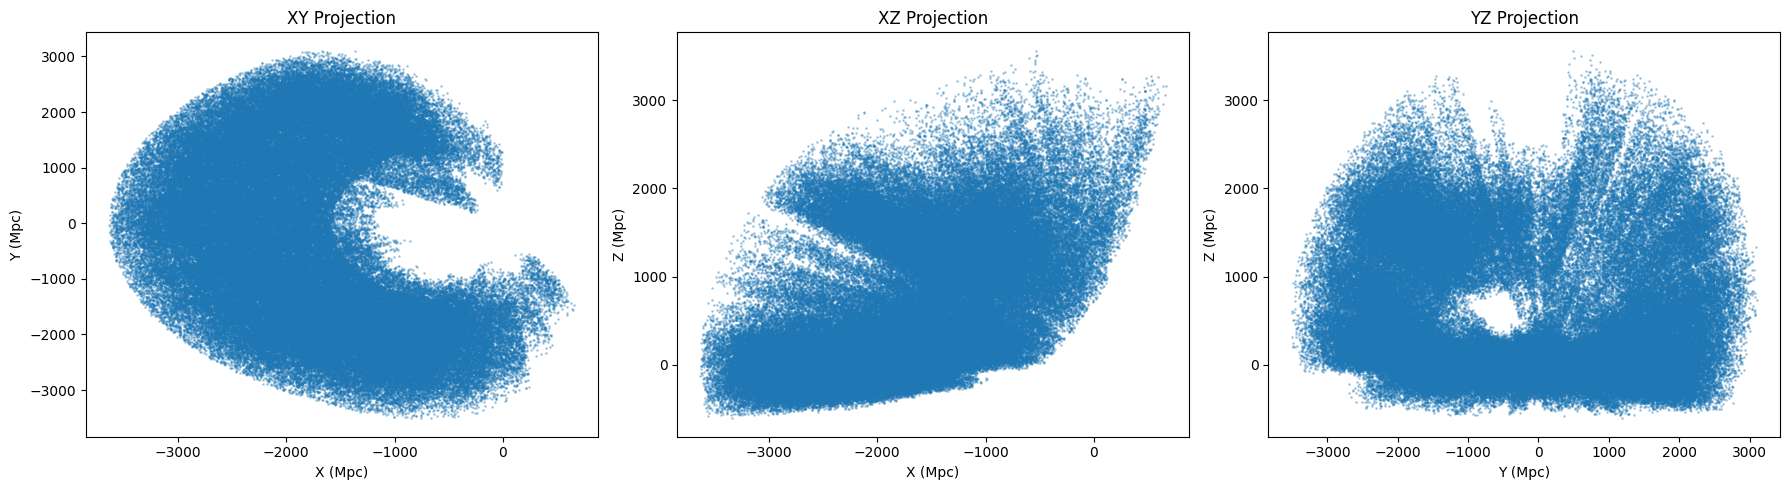

In [13]:
import numpy as np
import matplotlib.pyplot as plt

print("Galaxy array sizes:", x_g.shape, y_g.shape, z_g.shape)

# Random subsample for plotting
N = min(200000, len(x_g))
idx = np.random.choice(len(x_g), size=N, replace=False)

xs = x_g[idx]
ys = y_g[idx]
zs = z_g[idx]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].scatter(xs, ys, s=1, alpha=0.3)
axs[0].set_title("XY Projection")
axs[0].set_xlabel("X (Mpc)")
axs[0].set_ylabel("Y (Mpc)")

axs[1].scatter(xs, zs, s=1, alpha=0.3)
axs[1].set_title("XZ Projection")
axs[1].set_xlabel("X (Mpc)")
axs[1].set_ylabel("Z (Mpc)")

axs[2].scatter(ys, zs, s=1, alpha=0.3)
axs[2].set_title("YZ Projection")
axs[2].set_xlabel("Y (Mpc)")
axs[2].set_ylabel("Z (Mpc)")

plt.tight_layout()
plt.show()


In [14]:
L = 1000.0
half = L/2

xc, yc, zc = -1807.7, 0.0, 0.0

xmin, xmax = xc - half, xc + half
ymin, ymax = yc - half, yc + half
zmin, zmax = zc - half, zc + half

# Galaxy mask
mask_g = (
    (x_g > xmin) & (x_g < xmax) &
    (y_g > ymin) & (y_g < ymax) &
    (z_g > zmin) & (z_g < zmax)
)
print("Galaxies in cube:", mask_g.sum())

# Random mask
mask_r = (
    (x_r > xmin) & (x_r < xmax) &
    (y_r > ymin) & (y_r < ymax) &
    (z_r > zmin) & (z_r < zmax)
)
print("Randoms in cube:", mask_r.sum())


Galaxies in cube: 49162
Randoms in cube: 572974


In [15]:
import numpy as np
from astropy.io import fits
from astropy.cosmology import Planck15 as cosmo

# =====================================================
# 1. Load data
# =====================================================
gal = fits.open("/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_clustering.dat.fits")[1].data
ran0 = fits.open("/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_0_clustering.ran.fits")[1].data
ran1 = fits.open("/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_1_clustering.ran.fits")[1].data

ran = np.hstack([ran0, ran1])

print("Galaxies:", len(gal))
print("Randoms:", len(ran))

# =====================================================
# 2. Convert RA,DEC,Z → XYZ for galaxies
# =====================================================
def radec_to_xyz(ra, dec, z):
    ra = np.radians(ra)
    dec = np.radians(dec)
    chi = cosmo.comoving_distance(z).value
    x = chi * np.cos(dec) * np.cos(ra)
    y = chi * np.cos(dec) * np.sin(ra)
    z = chi * np.sin(dec)
    return x, y, z

xg, yg, zg = radec_to_xyz(gal["RA"], gal["DEC"], gal["Z"])
xr, yr, zr = radec_to_xyz(ran["RA"], ran["DEC"], ran["Z"])

# =====================================================
# 3. Test multiple cube sizes
# =====================================================
cube_sizes = [800, 900, 1000, 1100]  # Mpc side lengths
xc, yc, zc = -1807.7, 0, 0           # BEST CENTER FOUND

for L in cube_sizes:
    half = L / 2
    xmin, xmax = xc - half, xc + half
    ymin, ymax = yc - half, yc + half
    zmin, zmax = zc - half, zc + half

    mask_g = (xg > xmin) & (xg < xmax) & (yg > ymin) & (yg < ymax) & (zg > zmin) & (zg < zmax)
    mask_r = (xr > xmin) & (xr < xmax) & (yr > ymin) & (yr < ymax) & (zr > zmin) & (zr < zmax)

    Ng = np.sum(mask_g)
    Nr = np.sum(mask_r)

    print(f"\n===== Cube L = {L} Mpc =====")
    print(f"Galaxies in cube: {Ng}")
    print(f"Randoms in cube:  {Nr}")
    print(f"Ratio g/r: {Ng/Nr:.4f}")


Galaxies: 1476135
Randoms: 18774199

===== Cube L = 800 Mpc =====
Galaxies in cube: 32811
Randoms in cube:  371650
Ratio g/r: 0.0883

===== Cube L = 900 Mpc =====
Galaxies in cube: 40578
Randoms in cube:  464677
Ratio g/r: 0.0873

===== Cube L = 1000 Mpc =====
Galaxies in cube: 49162
Randoms in cube:  572974
Ratio g/r: 0.0858

===== Cube L = 1100 Mpc =====
Galaxies in cube: 58799
Randoms in cube:  698456
Ratio g/r: 0.0842


In [16]:
import numpy as np
from astropy.io import fits
from astropy.cosmology import Planck15 as cosmo

# Paths
gal_file = "/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_clustering.dat.fits"
ran0_file = "/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_0_clustering.ran.fits"
ran1_file = "/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_1_clustering.ran.fits"

# Load galaxies
gal = fits.open(gal_file)[1].data
print("Galaxies loaded:", len(gal))

# Load randoms (merge)
ran0 = fits.open(ran0_file)[1].data
ran1 = fits.open(ran1_file)[1].data

ran = np.hstack([ran0, ran1])
print("Randoms loaded:", len(ran))


Galaxies loaded: 1476135
Randoms loaded: 18774199


In [17]:
# Galaxies
ra_g  = np.radians(gal["RA"])
dec_g = np.radians(gal["DEC"])
z_g   = gal["Z"]

chi_g = cosmo.comoving_distance(z_g).value

x_g = chi_g*np.cos(dec_g)*np.cos(ra_g)
y_g = chi_g*np.cos(dec_g)*np.sin(ra_g)
z_g = chi_g*np.sin(dec_g)

# Randoms
ra_r  = np.radians(ran["RA"])
dec_r = np.radians(ran["DEC"])
z_r   = ran["Z"]

chi_r = cosmo.comoving_distance(z_r).value

x_r = chi_r*np.cos(dec_r)*np.cos(ra_r)
y_r = chi_r*np.cos(dec_r)*np.sin(ra_r)
z_r = chi_r*np.sin(dec_r)


In [18]:
xc, yc, zc = -1807.7, 0, 0
L = 1000
half = L/2

xmin, xmax = xc - half, xc + half
ymin, ymax = yc - half, yc + half
zmin, zmax = zc - half, zc + half


In [19]:
mask_g = (
    (x_g > xmin) & (x_g < xmax) &
    (y_g > ymin) & (y_g < ymax) &
    (z_g > zmin) & (z_g < zmax)
)

mask_r = (
    (x_r > xmin) & (x_r < xmax) &
    (y_r > ymin) & (y_r < ymax) &
    (z_r > zmin) & (z_r < zmax)
)

xg, yg, zg = x_g[mask_g], y_g[mask_g], z_g[mask_g]
xr, yr, zr = x_r[mask_r], y_r[mask_r], z_r[mask_r]

print("Galaxies in cube:", len(xg))
print("Randoms in cube:", len(xr))


Galaxies in cube: 49162
Randoms in cube: 572974


In [20]:
xg -= xmin; yg -= ymin; zg -= zmin
xr -= xmin; yr -= ymin; zr -= zmin


In [21]:
Ngrid = 256
dx = L / Ngrid

rho_g = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.float32)
rho_r = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.float32)

# convert to index
ixg = np.clip((xg/dx).astype(int), 0, Ngrid-1)
iyg = np.clip((yg/dx).astype(int), 0, Ngrid-1)
izg = np.clip((zg/dx).astype(int), 0, Ngrid-1)

ixr = np.clip((xr/dx).astype(int), 0, Ngrid-1)
iyr = np.clip((yr/dx).astype(int), 0, Ngrid-1)
izr = np.clip((zr/dx).astype(int), 0, Ngrid-1)

for i,j,k in zip(ixg, iyg, izg):
    rho_g[i,j,k] += 1

for i,j,k in zip(ixr, iyr, izr):
    rho_r[i,j,k] += 1


In [22]:
alpha = len(xg) / len(xr)
delta = (rho_g - alpha*rho_r) / (alpha*rho_r + 1e-6)


In [26]:
from scipy.ndimage import gaussian_filter

sigma = 5.0 / dx
delta_s = gaussian_filter(delta, sigma=sigma)
import numpy.fft as fft
import numpy as np

# Fourier transform of δ
delta_k = fft.fftn(delta_s)

# k-vectors
kx = fft.fftfreq(Ngrid) * 2*np.pi
ky = fft.fftfreq(Ngrid) * 2*np.pi
kz = fft.fftfreq(Ngrid) * 2*np.pi

kx, ky, kz = np.meshgrid(kx, ky, kz, indexing='ij')

k2 = kx**2 + ky**2 + kz**2
k2[0,0,0] = 1e-6   # avoid division by zero

# Poisson equation: φ_k = -δ_k / k^2
phi_k = -delta_k / k2

phi = fft.ifftn(phi_k).real
print("Potential φ min/max:", phi.min(), phi.max())
# components in k-space
Txx_k = -(kx*kx)*phi_k
Tyy_k = -(ky*ky)*phi_k
Tzz_k = -(kz*kz)*phi_k
Txy_k = -(kx*ky)*phi_k
Txz_k = -(kx*kz)*phi_k
Tyz_k = -(ky*kz)*phi_k

# back to real space
Txx = fft.ifftn(Txx_k).real
Tyy = fft.ifftn(Tyy_k).real
Tzz = fft.ifftn(Tzz_k).real
Txy = fft.ifftn(Txy_k).real
Txz = fft.ifftn(Txz_k).real
Tyz = fft.ifftn(Tyz_k).real

print("Txx min/max:", Txx.min(), Txx.max())
print("Tyy min/max:", Tyy.min(), Tyy.max())
print("Tzz min/max:", Tzz.min(), Tzz.max())
env_map = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.int8)

for i in range(Ngrid):
    for j in range(Ngrid):
        for k in range(Ngrid):

            T = np.array([
                [Txx[i,j,k], Txy[i,j,k], Txz[i,j,k]],
                [Txy[i,j,k], Tyy[i,j,k], Tyz[i,j,k]],
                [Txz[i,j,k], Tyz[i,j,k], Tzz[i,j,k]]
            ])

            w = np.linalg.eigvalsh(T)
            w = np.sort(w)[::-1]  # λ1 ≥ λ2 ≥ λ3

            if w[0] < 0 and w[1] < 0 and w[2] < 0:
                env_map[i,j,k] = 0     # VOID
            elif w[0] > 0 and w[1] < 0 and w[2] < 0:
                env_map[i,j,k] = 1     # SHEET
            elif w[0] > 0 and w[1] > 0 and w[2] < 0:
                env_map[i,j,k] = 2     # FILAMENT
            elif w[0] > 0 and w[1] > 0 and w[2] > 0:
                env_map[i,j,k] = 3     # CLUSTER


Potential φ min/max: -2716085228.3342576 -2699355191.2370367
Txx min/max: -59922.12373663545 119696.71388720063
Tyy min/max: -91387.77511863521 198495.17540271522
Tzz min/max: -31785.059147889842 103670.44433753467


In [28]:
unique, counts = np.unique(env_map, return_counts=True)
frac = counts / counts.sum() * 100

print("Environment fractions (%):")
for u, f in zip(unique, frac):
    name = ["Void","Sheet","Filament","Cluster"][u]
    print(f"{name:<8}: {f:6.2f}%")
import h5py

save_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5"

with h5py.File(save_path, "w") as f:
    f["env_map"] = env_map
    f["delta"] = delta_s
    f.attrs["Ngrid"] = Ngrid
    f.attrs["L"] = L
    f.attrs["xc"] = xc
    f.attrs["yc"] = yc
    f.attrs["zc"] = zc

print("Saved T-Web cube →", save_path)


Environment fractions (%):
Void    :   7.45%
Sheet   :  53.98%
Filament:  36.09%
Cluster :   2.48%
Saved T-Web cube → /home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5


Loaded: (256, 256, 256) Ngrid = 256 L = 1000


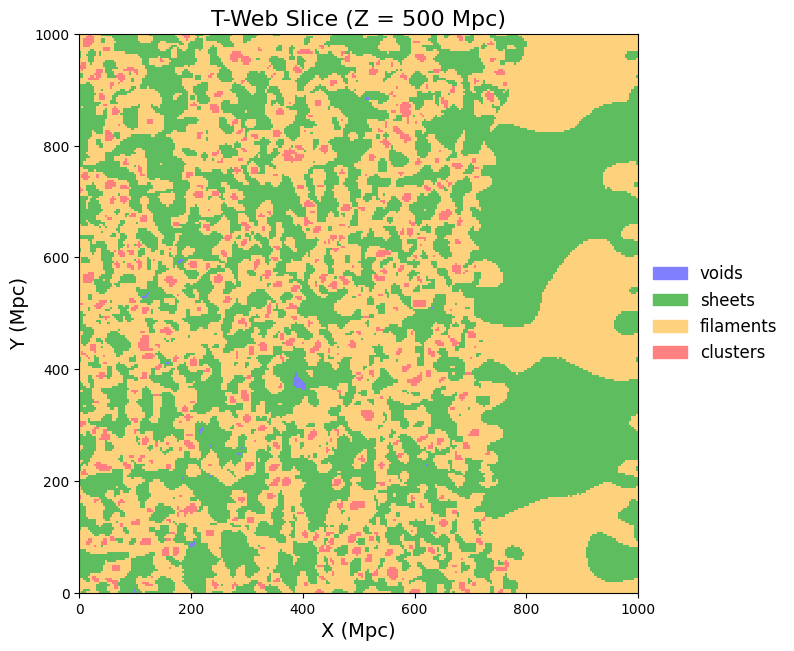

Saved: /home/qarni/galaxy_evolution_project/LRG/tweb_slice_BORG_style.png


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

# ============================
# 1) Load the T-Web cube
# ============================
file_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5"

with h5py.File(file_path, "r") as f:
    env_map = f["env_map"][:]     # (256,256,256) classification
    Ngrid   = f.attrs["Ngrid"]
    L       = f.attrs["L"]

print("Loaded:", env_map.shape, "Ngrid =", Ngrid, "L =", L)

# ============================
# 2) Mid-Z slice
# ============================
mid = Ngrid // 2
slice_xy = env_map[:, :, mid]

# ============================
# 3) BORG SDSS Colors (exact)
# ============================
void_blue         = (128/256, 128/256, 255/256, 1.0)
sheet_green       = ( 95/256, 190/256,  95/256, 1.0)
filament_yellow   = (255/256, 210/256, 126/256, 1.0)
cluster_red       = (255/256, 128/256, 128/256, 1.0)

# OPTIONAL: if 0 = undecided → black
undecided_black   = (0, 0, 0, 1.0)

# Order must match: 0,1,2,3
StructuresMap = ListedColormap([
    void_blue,        # 0 = Void
    sheet_green,      # 1 = Sheet
    filament_yellow,  # 2 = Filament
    cluster_red       # 3 = Cluster
])

# ============================
# 4) Plot
# ============================
plt.figure(figsize=(8,8))

plt.imshow(
    slice_xy.T,
    origin="lower",
    extent=[0, L, 0, L],
    cmap=StructuresMap,
    interpolation="nearest"
)

plt.xlabel("X (Mpc)", fontsize=14)
plt.ylabel("Y (Mpc)", fontsize=14)
plt.title(f"T-Web Slice (Z = {L/2:.0f} Mpc)", fontsize=16)

# ============================
# 5) Legend (same as BORG)
# ============================
v_patch = mpatches.Patch(color=void_blue, label='voids')
s_patch = mpatches.Patch(color=sheet_green, label='sheets')
f_patch = mpatches.Patch(color=filament_yellow, label='filaments')
c_patch = mpatches.Patch(color=cluster_red, label='clusters')

plt.legend(
    handles=[v_patch, s_patch, f_patch, c_patch],
    frameon=False,
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    fontsize=12
)

plt.tight_layout()

# ============================
# 6) Save
# ============================
savepath = "/home/qarni/galaxy_evolution_project/LRG/tweb_slice_BORG_style.png"
plt.savefig(savepath, dpi=300, bbox_inches='tight')
plt.show()

print("Saved:", savepath)


Loaded: (256, 256, 256) Grid = 256 Box = 1000


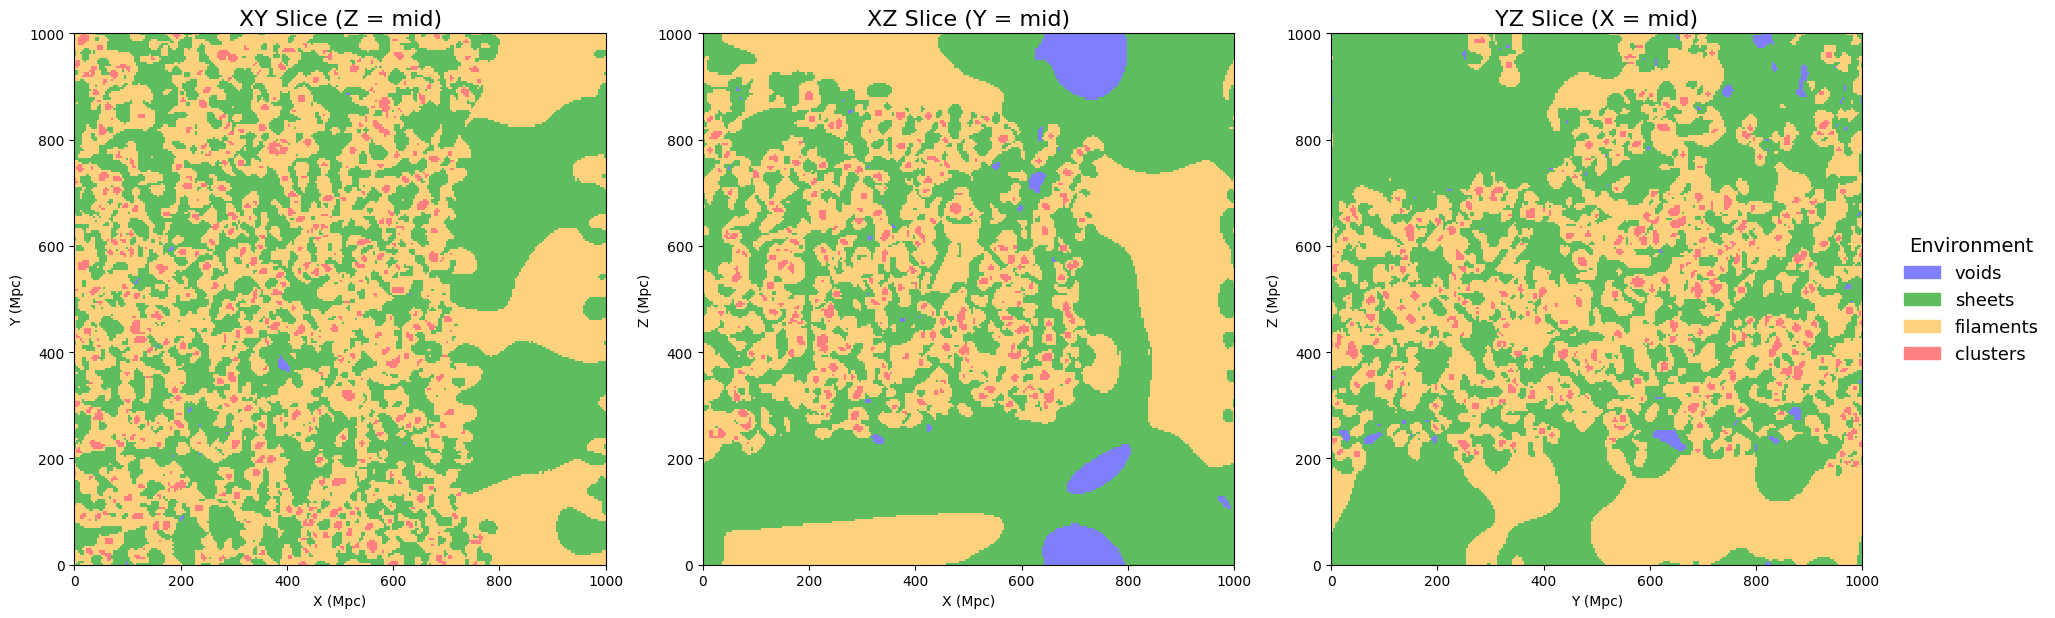

Saved: /home/qarni/galaxy_evolution_project/LRG/tweb_multi_slice_BORG.png


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

# ============================
# 1) Load T-Web cube
# ============================
file_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5"

with h5py.File(file_path, "r") as f:
    env_map = f["env_map"][:]    # (Ngrid,Ngrid,Ngrid)
    Ngrid   = f.attrs["Ngrid"]
    L       = f.attrs["L"]

print("Loaded:", env_map.shape, "Grid =", Ngrid, "Box =", L)

# Mid-slices
ix = iy = iz = Ngrid // 2

slice_xy = env_map[:, :, iz]      # Z fixed
slice_xz = env_map[:, iy, :]      # Y fixed
slice_yz = env_map[ix, :, :]      # X fixed

# ============================
# 2) BORG SDSS Colors
# ============================
void_blue         = (128/256,128/256,255/256,1.)
sheet_green       = ( 95/256,190/256, 95/256,1.)
filament_yellow   = (255/256,210/256,126/256,1.)
cluster_red       = (255/256,128/256,128/256,1.)

StructuresMap = ListedColormap([
    void_blue,
    sheet_green,
    filament_yellow,
    cluster_red
])

# ============================
# 3) Plot 3 slices
# ============================
fig, axs = plt.subplots(1, 3, figsize=(20, 7))

# --- XY Slice ---
axs[0].imshow(
    slice_xy.T,
    origin="lower",
    cmap=StructuresMap,
    extent=[0, L, 0, L],
    interpolation="nearest"
)
axs[0].set_title("XY Slice (Z = mid)", fontsize=16)
axs[0].set_xlabel("X (Mpc)")
axs[0].set_ylabel("Y (Mpc)")

# --- XZ Slice ---
axs[1].imshow(
    slice_xz.T,
    origin="lower",
    cmap=StructuresMap,
    extent=[0, L, 0, L],
    interpolation="nearest"
)
axs[1].set_title("XZ Slice (Y = mid)", fontsize=16)
axs[1].set_xlabel("X (Mpc)")
axs[1].set_ylabel("Z (Mpc)")

# --- YZ Slice ---
axs[2].imshow(
    slice_yz.T,
    origin="lower",
    cmap=StructuresMap,
    extent=[0, L, 0, L],
    interpolation="nearest"
)
axs[2].set_title("YZ Slice (X = mid)", fontsize=16)
axs[2].set_xlabel("Y (Mpc)")
axs[2].set_ylabel("Z (Mpc)")

# ============================
# 4) Legend
# ============================
v_patch = mpatches.Patch(color=void_blue, label='voids')
s_patch = mpatches.Patch(color=sheet_green, label='sheets')
f_patch = mpatches.Patch(color=filament_yellow, label='filaments')
c_patch = mpatches.Patch(color=cluster_red, label='clusters')

fig.legend(
    handles=[v_patch, s_patch, f_patch, c_patch],
    loc="center right",
    bbox_to_anchor=(1.03, 0.5),
    frameon=False,
    fontsize=13,
    title="Environment",
    title_fontsize=14
)

plt.tight_layout(rect=[0, 0, 0.95, 1])

# ============================
# 5) Save
# ============================
savepath = "/home/qarni/galaxy_evolution_project/LRG/tweb_multi_slice_BORG.png"
plt.savefig(savepath, dpi=300, bbox_inches='tight')
plt.show()

print("Saved:", savepath)


Loaded env_map: (256, 256, 256)


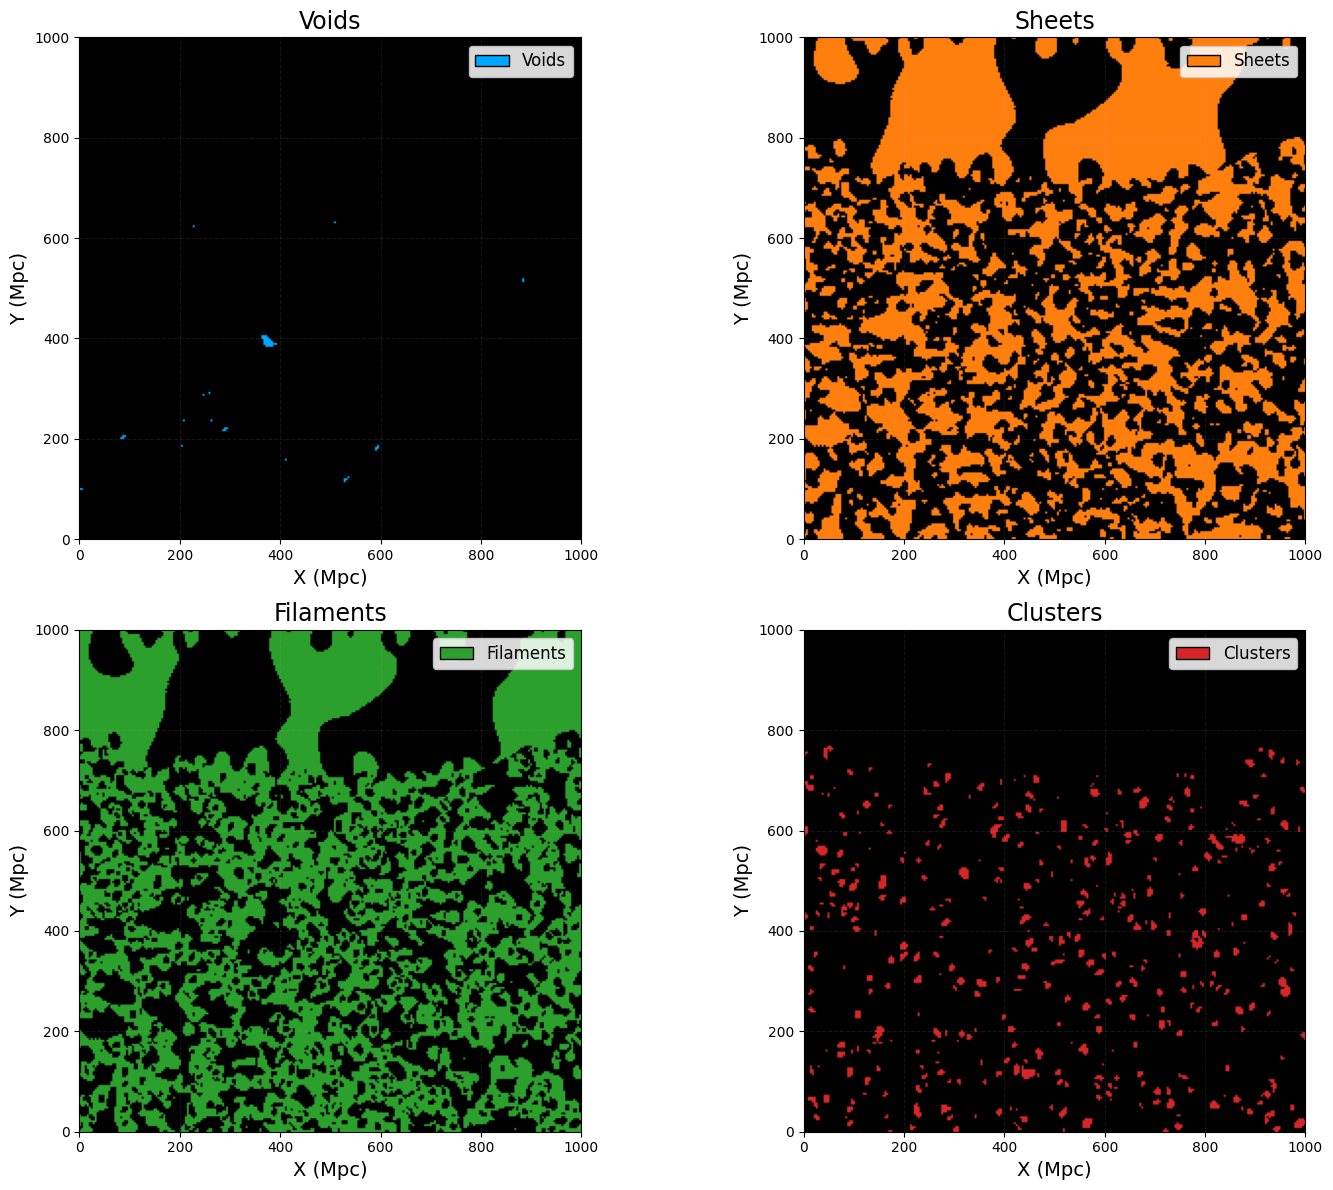

Saved to: /home/qarni/galaxy_evolution_project/LRG/tweb_panels_clean_final.png


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

# ============================
# 1) Load T-Web file
# ============================
file_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5"

with h5py.File(file_path, "r") as f:
    env_map = f["env_map"][:]     # cosmic web map
    Ngrid   = f.attrs["Ngrid"]
    L       = f.attrs["L"]

print("Loaded env_map:", env_map.shape)

# ============================
# 2) Extract mid slice
# ============================
mid = Ngrid // 2
slice_data = env_map[:, :, mid]

# ============================
# 3) Colors (VOID = strong neon blue)
# ============================
colors_hex = [
    "#00a6ff",  # Void
    "#ff7f0e",  # Sheet
    "#2ca02c",  # Filament
    "#d62728",  # Cluster
]

env_names = ["Voids", "Sheets", "Filaments", "Clusters"]

# RGB conversion
colors_rgb = np.array([plt.matplotlib.colors.to_rgb(c) for c in colors_hex])

# ============================
# 4) 2×2 Panels
# ============================
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for env_idx, ax in enumerate(axes):
    mask = (slice_data == env_idx)

    # RGB image layer
    rgb_img = np.zeros((*slice_data.shape, 3))
    for i in range(3):
        rgb_img[..., i] = np.where(mask, colors_rgb[env_idx, i], 0.0)

    ax.imshow(
        rgb_img,
        origin="lower",
        extent=[0, L, 0, L]
    )

    # ========== PANEL TITLE ==========
    ax.set_title(env_names[env_idx], fontsize=17)

    ax.set_xlabel("X (Mpc)", fontsize=14)
    ax.set_ylabel("Y (Mpc)", fontsize=14)
    ax.grid(alpha=0.12, linestyle="--")

    # ========== LEGEND INSIDE PANEL ==========
    patch = Patch(
        facecolor=colors_hex[env_idx],
        edgecolor="black",
        label=env_names[env_idx]
    )

    ax.legend(
        handles=[patch],
        loc="upper right",
        fontsize=12,
        framealpha=0.85
    )


plt.tight_layout()

savepath = "/home/qarni/galaxy_evolution_project/LRG/tweb_panels_clean_final.png"
plt.savefig(savepath, dpi=300, bbox_inches='tight')
plt.show()

print("Saved to:", savepath)


In [6]:
import h5py

file_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5"

with h5py.File(file_path, "r") as f:
    print("Keys inside file:")
    for k in f.keys():
        print(" -", k)

    print("\nAttributes:")
    for a in f.attrs:
        print(a, "=", f.attrs[a])


Keys inside file:
 - delta
 - env_map

Attributes:
L = 1000
Ngrid = 256
xc = -1807.7
yc = 0
zc = 0


In [26]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_L1000.h5"

with h5py.File(file_path, "r") as f:
    delta = f["delta"][:]
    env = f["env_map"][:]

print("Delta shape:", delta.shape)
print("Min delta:", delta.min())
print("Max delta:", delta.max())
print("Mean delta:", delta.mean())

# Histogram
plt.figure(figsize=(5.5))
plt.hist(delta.flatten(), bins=200, color='purple')
plt.xlabel("δ"); plt.ylabel("Voxels")
plt.title("Density Contrast Histogram")
plt.show()
unique, counts = np.unique(env, return_counts=True)
for u,c in zip(unique, counts):
    print(f"Environment {u}: {c} voxels ({c/env.size*100:.2f}%)")
Ngal = mask.sum()
voxels = 256**3
print("Avg galaxies per voxel:", Ngal/voxels)


Delta shape: (256, 256, 256)
Min delta: -0.28973314
Max delta: 382307.25
Mean delta: 2705.961


TypeError: Value after * must be an iterable, not float